# Budget versus Actuals - step-by-step project notebook

**Business Analytics Workshop | CookieSensei Labs | Python 3.12**

Work through **what we are doing, why it is useful, how the code works, and what its output means**. The explanations are Markdown cells, and the analysis is in editable Python code cells with saved results. All records are fictional teaching data; monetary values are INR.

Keep this notebook with [department_budget.csv](department_budget.csv) and [app.py](app.py). The [Markdown companion](EXPLANATION.md) provides a continuous reading version. The source application and data used here match revision `c10a61c36fffdd048b69dd78926e6663bc986fce`.

## Learning route: turn spending records into a defensible explanation

Your job in this notebook is to help a budget owner decide **where to investigate a spending gap**. Name the period, explain the comparison, and point back to the records.

By the end, you should be able to:

- Describe the population behind an expense total and reproduce it with filters.
- Explain why `budget - actual` has a business interpretation, including its sign.
- Distinguish overspent lines, net variance, and utilization; choose the denominator that answers your question.
- Move from individual records to monthly and departmental summaries without confusing their units.
- Connect a pandas calculation to a Streamlit control, card, chart, or downloadable result.

**Start with the row grain.** One row in [department_budget.csv](department_budget.csv) describes one department and expense category for one recorded month. It is a monthly budget line, not an invoice or employee. Its `month` is a first-of-month label. Restricting dates selects these whole records; it does not prorate a monthly budget. Check the business keys again when replacing the data.

| Tool | Responsibility in this project | Why it helps you reason |
| --- | --- | --- |
| `Path` | Locate the CSV | Makes the data source explicit. |
| pandas | Parse columns, select rows, derive variance, group and summarize | Keeps the same named fields through the analysis and lets you inspect each intermediate table. |
| Plotly | Interactive monthly and departmental charts | Connects visual comparisons to values available on hover. |
| Matplotlib and Seaborn | Histogram, boxplot, and heatmap | Exposes distributions and combinations concealed by a single total. |
| Streamlit | Collect selections and display calculated results | Lets another person repeat the analysis through browser controls. |

Workflow: **define the question, choose the population, calculate at the correct grain, compare, then explain the limits**.

## How to work through this notebook

1. Open `TUTORIAL.ipynb` in JupyterLab or VS Code and select the workshop's Python 3.12 environment.
2. Read the question above a code cell, predict the result, then use **Shift+Enter** to run that cell.
3. Run cells from top to bottom. Python variables stay in the kernel's memory; changing an earlier cell requires rerunning the cells that depend on it.
4. Compare the output with the interpretation underneath. Try the checkpoints before moving on.
5. Use **Restart Kernel and Run All Cells** to reproduce the baseline from a clean session. All executable cells here finish without launching a long-running web server.

The first code cell locates this project and configures notebook chart display. It supports starting in the project folder, the workshop folder, or the repository root. It changes only the kernel's working directory; it does not move any files.

The complete Streamlit teaching script later in this notebook is a **reference code block in a Markdown cell**. Copy it into the stated separate `.py` file to launch its browser interface. The runnable `AppTest` section independently inspects the existing `app.py` and demonstrates a filter rerun inside the notebook. These two execution contexts are explained separately.

Saved figure outputs include embedded PNG previews. In a running JupyterLab or VS Code notebook, Plotly can also display interactive figures. A GitHub preview shows the saved notebook and cannot execute Python. Keep the CSV and app beside the notebook when downloading it for execution. Local JupyterLab users can install the notebook interface with `python -m pip install jupyterlab`; the prepared Cloud Lab already supplies it. Analysis package versions are listed in the [workshop setup](../README.md).

In [1]:
from pathlib import Path                  # Represent a folder or filename as a Python object.
import os                                # Change this kernel's working directory when necessary.
import sys                               # Inspect the Python version selected by the kernel.
from IPython.display import display      # Render tables and figures as notebook outputs.
import matplotlib
import plotly.io as pio

# Support opening the notebook from this folder, the workshop, or the repo root.
notebook_start = Path.cwd()
candidate_folders = [
    notebook_start,
    notebook_start / '05_finance_budget',
    notebook_start / 'business_analytics_workshop' / '05_finance_budget',
]
PROJECT_DIR = next(
    (folder for folder in candidate_folders
     if (folder / 'department_budget.csv').is_file() and (folder / 'app.py').is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError('Open this notebook with its sibling CSV and app.py in the project folder.')
PROJECT_DIR = PROJECT_DIR.resolve()
os.chdir(PROJECT_DIR)

# Inline figures belong below their code cells; the Plotly renderer is used by JupyterLab/VS Code.
matplotlib.use('module://matplotlib_inline.backend_inline')
pio.renderers.default = 'plotly_mimetype'
print('Project folder:', PROJECT_DIR.name)
print('CSV and app.py found.')
print('Python:', sys.version.split()[0])

Project folder: 05_finance_budget
CSV and app.py found.
Python: 3.12.14


### Python vocabulary you will use repeatedly

| Code pattern | What it means | Why it appears here |
| --- | --- | --- |
| `name = expression` | Calculate a value and give it a name | Later cells can reuse the result |
| `import pandas as pd` | Import a library with a short alias | `pd.read_csv(...)` calls its CSV reader |
| `frame["column"]` | Select one named column as a Series | Apply a calculation to that measure |
| `frame[mask]` | Keep rows whose Boolean condition is `True` | Define the population being analyzed |
| `.method(...)` | Ask an object to perform an operation | `.sum()`, `.mean()` and `.groupby()` answer different questions |
| `# explanation` | A comment Python does not execute | Describe the purpose of the next operation |
| `f"...{value:.2f}..."` | Put a formatted value into a string | Communicate results without changing the underlying value |

Indentation groups statements inside a `for`, `if`, function or `with` block. Brackets, parentheses and column spelling matter. When a cell fails, read the final error message, inspect the named variable or column, and fix the earliest failed step before continuing.

## The business question

A manager needs to know whether recorded expenses exceed the approved plan, which departments or categories explain the gap, and which owners should investigate. A single company total can hide offsetting differences: one line overspends while another remains under budget. Large spending is also different from poor budget adherence; a large department may have a proportionally large approved plan.

This project therefore connects **total amounts, percentage utilization, individual lines, department/month groups, and distributions**. It produces questions for follow-up rather than deciding that an expense was wasteful. The dataset contains no income, commitments, cash timing, or business output, so it cannot calculate profit, available cash, or whether the expense was justified.

One row is one **month/department/expense-category budget line**. It is not one purchase or one employee. The `month` field uses the first day as a label for the whole recorded month; selecting part of a calendar month does not prorate its budget.

| Field | Business meaning |
| --- | --- |
| `month` | Month label, recorded on its first day |
| `department` | Department responsible for the expense |
| `expense_category` | Expense classification |
| `budget` | Planned expense for that line, INR |
| `actual` | Recorded expense for that line, INR |

**Why pandas?** A `DataFrame` stores the CSV as named columns and rows. Its selection, date parsing, grouping, and arithmetic let us express the question directly: group by department, then add planned and recorded expense. Python loops could also do the job; pandas avoids repeatedly implementing table bookkeeping. The analyst still has to choose the correct grain, denominator, and interpretation.

## Prepare and inspect the data

Use Python 3.12 and the versions in the [workshop setup](../README.md). From the repository root in a Linux/macOS terminal:

```bash
python -m venv .venv
source .venv/bin/activate
python -m pip install streamlit==1.50.0 pandas==2.2.3 numpy==2.3.5 matplotlib==3.10.8 seaborn==0.13.2 plotly==6.5.2
cd business_analytics_workshop/05_finance_budget
```

Select this environment as the notebook kernel, or use its Python console. If a notebook tool is not installed, install/use JupyterLab or VS Code's notebook support separately. The prepared CookieSensei workshop workspace already supplies the analysis environment. For a full Windows checkout, follow the [repository README](../../README.md) and use WSL or the Linux Cloud Lab because other phase-folder names contain `>`. The figures below are captured PNGs; creating the same interactive Plotly figures with `fig` does not require an image-export package.

### Step 01 - Import the tools and locate the CSV

**Question:** Which tools do we need, and have we opened the correct project folder?

In [2]:
from pathlib import Path             # Build file paths without hard-coding a machine.
import pandas as pd                  # Work with tables, dates, and grouped calculations.
import matplotlib.pyplot as plt      # Create figures/axes and draw a histogram.
import seaborn as sns                # Draw statistical boxes and a matrix heatmap.
import plotly.express as px          # Build interactive line and bar figures.

DATA_FILE = Path('department_budget.csv')  # Notebook cells run from this folder.
print(f'Dataset: {DATA_FILE.name}')
print(f'File exists: {DATA_FILE.is_file()}')

Dataset: department_budget.csv
File exists: True


**Interpretation and reasoning**

The aliases `pd`, `plt`, `sns`, and `px` are short module names. In a notebook, `__file__` is usually unavailable, so this cell uses the stated working directory. The actual app uses `Path(__file__).resolve().with_name(...)` because a saved script has its own filename. pandas handles values; plotting libraries encode them visually. Streamlit is introduced only when we build the browser interface.

### Step 02 - Load real records and read their meaning

**Question:** What does the input actually contain?

In [3]:
frame = pd.read_csv(DATA_FILE)         # Parse the CSV header and records into a DataFrame.
print(f'Rows: {len(frame)} | Columns: {len(frame.columns)}')
print(frame.head(4).to_string(index=False))  # Inspect a small real sample, not the whole file.

Rows: 192 | Columns: 5
     month department expense_category  budget    actual
2025-01-01      Sales           People  112000 131473.15
2025-01-01      Sales         Software   82000 111991.54
2025-01-01      Sales           Travel  172000 119684.36
2025-01-01      Sales       Facilities   56000  59246.32


### Notebook skill - inspect a table directly

The printed preview above is useful in scripts and text reports. A notebook can also render the DataFrame itself as a table. `head(5)` returns a small view for inspection; it does not replace the full source table. Compare the row labels on the left with any business identifier column.

In [4]:
# Display the same source as a notebook table; keep frame unchanged.
display(frame.head(5))

,month,department,expense_category,budget,actual
0,2025-01-01,Sales,People,112000,131473.15
1,2025-01-01,Sales,Software,82000,111991.54
2,2025-01-01,Sales,Travel,172000,119684.36
3,2025-01-01,Sales,Facilities,56000,59246.32
4,2025-01-01,Engineering,People,109000,150863.92


**Interpretation and reasoning**

The first line describes Sales / People for January: INR 112,000 planned and INR 131,473.15 recorded. January 1 is a month label, not proof that the expense was paid that day. `head(4)` is inspection only; it does not replace `frame` with four rows. `index=False` hides pandas row labels in the printed table.

### Step 03 - Check the grain before counting or aggregating

**Question:** Does each row represent the level of detail we intend to analyze?

In [5]:
# A business key describes one intended month/department/category combination.
key = ['month', 'department', 'expense_category']
print(f'Month labels: {frame["month"].nunique()}')
print(f'Departments: {frame["department"].nunique()}')
print(f'Expense categories: {frame["expense_category"].nunique()}')
print(f'Repeated business keys: {frame.duplicated(subset=key).sum()}')
print('Departments:', ', '.join(sorted(frame['department'].unique())))

Month labels: 12
Departments: 4
Expense categories: 4
Repeated business keys: 0
Departments: Customer Success, Engineering, Operations, Sales


**Interpretation and reasoning**

Twelve months times four departments times four categories explains the 192 lines. Counting rows measures budget lines, not purchases or employees. The repeated-key calculation is an **additional diagnostic**; the original app counts exact duplicate rows but does not enforce this business key. A repeated key might be a duplicate, a revision, or a legitimate subline; its meaning must be resolved before totals are trusted.

### Step 04 - Turn date and amount text into usable types

**Question:** Can the computer compare dates and do arithmetic on expenses reliably?

In [6]:
# Dates become datetime values so comparisons are chronological.
frame['month'] = pd.to_datetime(frame['month'], errors='raise')

# An invalid numeric string raises an error instead of silently becoming a missing value.
numeric_columns = ['budget', 'actual']
for column in numeric_columns:
    frame[column] = pd.to_numeric(frame[column], errors='raise')

print(frame.dtypes.to_string())
print('Observed month labels:', frame['month'].min().date(), 'to', frame['month'].max().date())

month               datetime64[ns]
department                  object
expense_category            object
budget                       int64
actual                     float64
Observed month labels: 2025-01-01 to 2025-12-01


**Interpretation and reasoning**

A column that looks numeric in a spreadsheet can still be text. Explicit parsing makes the intended type clear. `errors="raise"` does not enforce nonnegative, finite, or economically plausible amounts; it addresses parsing. The final date is December 1 because the file represents December with its first-day label.

### Step 05 - Validate required values and inspect source quality

**Question:** Are essential fields present and filled, and what do the checks actually establish?

In [7]:
required = ['month', 'department', 'expense_category', 'budget', 'actual']
if not set(required).issubset(frame.columns):  # All required names must be present.
    raise ValueError('The CSV is missing required columns.')
if frame.empty:                              # A header alone is not an analyzable dataset.
    raise ValueError('The CSV contains no rows.')
if frame[required].isna().any().any():         # Reduce missing-cell flags across both axes.
    raise ValueError('Fill missing required values before analysis.')

quality = pd.DataFrame({
    'field': frame.columns,
    'type': frame.dtypes.astype(str).values,
    'missing': frame.isna().sum().values,
})
print(quality.to_string(index=False))
print(f'Exact duplicate rows: {frame.duplicated().sum()}')

           field           type  missing
           month datetime64[ns]        0
      department         object        0
expense_category         object        0
          budget          int64        0
          actual        float64        0
Exact duplicate rows: 0


**Interpretation and reasoning**

The checks match the original app's required-field/nonempty/missing-value policy. As in the app, parsing the month occurs before the required-column test, so a missing month header can raise a `KeyError` first. The app catches loading errors and displays them with `st.error`; this notebook lets the exception stop the cell. Zero missing/duplicate counts do not prove accounting accuracy. No records are automatically dropped or imputed.

## Filter records and calculate the business measures

### Checkpoint: define what the answer will describe

**Predict:** Which department/category records should survive the default selection? What happens if a date window begins halfway through January?

**Inspect:** Compare the selected-row count with the source count and inspect the actual `month` labels.

**Explain:** Complete this sentence before calculating a KPI: "My answer describes ___ budget lines, for ___ departments and categories, during ___."

### Step 06 - Reproduce the default analytical selection

**Question:** Which exact population do the following totals describe?

In [8]:
# These variables stand in for sidebar widget choices in the browser app.
selected_departments = sorted(frame['department'].unique())
selected_categories = sorted(frame['expense_category'].unique())
start_date = frame['month'].min().date()
end_date = frame['month'].max().date()

filtered = frame.copy()  # Keep the original table for source-quality reporting.
filtered = filtered[filtered['department'].isin(selected_departments)]
filtered = filtered[filtered['expense_category'].isin(selected_categories)]
filtered = filtered[filtered['month'].dt.date.between(start_date, end_date)]
if filtered.empty:
    raise ValueError('No rows match the chosen selection.')

print(f'Selected {len(filtered)} of {len(frame)} budget lines')
print(f'Inclusive date window: {start_date} to {end_date}')

Selected 192 of 192 budget lines
Inclusive date window: 2025-01-01 to 2025-12-01


**Interpretation and reasoning**

`.isin()` produces a Boolean mask; `filtered[mask]` keeps matching rows. Applying the three conditions sequentially means a row must satisfy all of them. `.between()` includes both endpoints. All values are selected here, so subsequent displayed outputs reproduce the default dashboard. Change the selection deliberately and rerun all later cells to explore another population.

### Step 07 - See a Boolean filter without changing the main selection

**Question:** How does a text choice become an actual row selection?

In [9]:
# This separate inspection table does not replace filtered.
operations_mask = frame['department'].isin(['Operations'])
operations = frame[operations_mask]
print('First eight membership flags:', operations_mask.head(8).tolist())
print(f'Operations lines: {len(operations)}')
print(operations.head(3).to_string(index=False))

First eight membership flags: [False, False, False, False, False, False, False, False]
Operations lines: 48
     month department expense_category  budget    actual
2025-01-01 Operations           People  166000 153352.45
2025-01-01 Operations         Software  141000 172797.34
2025-01-01 Operations           Travel  178000 235846.10


**Interpretation and reasoning**

Each flag answers whether one source row belongs to Operations. The mask retains 48 lines: 12 months times four categories. This cell creates a separate `operations` variable so the later all-data examples remain reproducible. In the actual Streamlit app, choosing Operations instead narrows `filtered` and changes every downstream result.

### Step 08 - Calculate one variance for each budget line

**Question:** Which records are above or below their plan?

In [10]:
# pandas subtracts corresponding values row by row, preserving the row labels.
filtered['variance'] = filtered['budget'] - filtered['actual']
print(filtered[['month', 'department', 'expense_category', 'budget', 'actual', 'variance']]
      .head(4).to_string(index=False))

     month department expense_category  budget    actual  variance
2025-01-01      Sales           People  112000 131473.15 -19473.15
2025-01-01      Sales         Software   82000 111991.54 -29991.54
2025-01-01      Sales           Travel  172000 119684.36  52315.64
2025-01-01      Sales       Facilities   56000  59246.32  -3246.32


**Interpretation and reasoning**

The first line is `112000 - 131473.15 = -19473.15`: negative variance means overspend. The Travel line is positive because its actual expense is below plan. This project deliberately uses **budget minus actual**; another sign convention would reverse the interpretation. The new column exists only in `filtered`, not in the source CSV or `frame`.

### Checkpoint: choose the sign and denominator

**Predict:** If actual expense rises while budget stays fixed, which direction should variance and utilization move?

**Inspect:** Trace one selected row through its derived `variance`, then compare that row with the totals in the next cells.

**Explain:** Why can many overspent lines coexist with a small net gap? Why should a large budget line have more influence on overall utilization than a small one? Keep "share of lines" separate from "share of money."

### Step 09 - Calculate the four dashboard KPIs

**Question:** Is the selected activity within its overall expense plan?

In [11]:
def ratio(numerator, denominator):  # This is the original app's scalar safeguard.
    return numerator / denominator if denominator else 0.0

budget = filtered['budget'].sum()   # Add planned expenses in the chosen population.
actual = filtered['actual'].sum()   # Add recorded expenses in the same population.
variance = budget - actual
utilization = ratio(actual, budget) # Divide totals, not individual percentage values.

print(f'Budget: INR {budget:,.2f}')
print(f'Actual expense: INR {actual:,.2f}')
print(f'Budget minus actual: INR {variance:,.2f}')
print(f'Budget utilization: {utilization:.2%}')

Budget: INR 22,011,000.00
Actual expense: INR 22,486,668.08
Budget minus actual: INR -475,668.08
Budget utilization: 102.16%


**Interpretation and reasoning**

Actual exceeds the budget by INR 475,668.08; utilization is slightly over 102%. `:.2%` converts the stored ratio to a percentage for display, so do not multiply by 100 before using that formatter. The helper returns a fallback zero for a zero denominator, which prevents a crash but does not make utilization mathematically defined when budget is zero. The bundled budgets are positive. Unspent budget is neither profit nor available cash.

### Step 10 - Demonstrate why utilization must use the money weights

**Question:** Why not average the utilization percentages of all rows?

In [12]:
# Compare two different questions using the actual selected budget lines.
line_rates = filtered['actual'].div(filtered['budget'].replace(0, float('nan')))
unweighted_mean = line_rates.mean()              # Each line receives equal influence.
weighted_mean = (line_rates * filtered['budget']).sum() / budget

print(f'Unweighted mean of line utilization: {unweighted_mean:.4%}')
print(f'Budget-weighted mean: {weighted_mean:.4%}')
print(f'Ratio of total actual to total budget: {actual / budget:.4%}')

Unweighted mean of line utilization: 102.5677%
Budget-weighted mean: 102.1610%
Ratio of total actual to total budget: 102.1610%


**Interpretation and reasoning**

This is a diagnostic extension using real source values. An unweighted mean gives a small budget line the same influence as a large one. Weighting by budget gives the same answer as dividing the total actual by the total budget, because the question concerns the money planned for the entire selection. The identity shown here uses this file's positive budgets; zero-budget lines require an explicit policy rather than quietly treating missing rates as valid.

### Step 11 - Count overspent lines before combining them

**Question:** Is overspending widespread or limited to a few lines?

In [13]:
overspent_mask = filtered['variance'] < 0       # True means this individual line is overspent.
overspent_lines = int(overspent_mask.sum())     # Summing Booleans counts True values.
print(f'Overspent lines: {overspent_lines} of {len(filtered)}')
print(f'Share of lines overspent: {overspent_lines / len(filtered):.1%}')
print(filtered.loc[overspent_mask, ['department', 'expense_category', 'variance']]
      .head(3).to_string(index=False))

Overspent lines: 109 of 192
Share of lines overspent: 56.8%
department expense_category  variance
     Sales           People -19473.15
     Sales         Software -29991.54
     Sales       Facilities  -3246.32


**Interpretation and reasoning**

109 of 192 lines are overspent, about 56.8%. This is a frequency measure: an INR 100 difference and an INR 50,000 difference each count as one line. It is not the share of expense that is over budget. Counting after departmental grouping would answer a different question: how many department totals are overspent.

### Step 12 - Separate gross overspending from offsetting underspending

**Question:** Can a modest net gap hide much larger differences underneath?

In [14]:
# Extension: the existing app reports net variance and counts, not these two extra totals.
gross_overspend = -filtered.loc[filtered['variance'] < 0, 'variance'].sum()
underspend = filtered.loc[filtered['variance'] > 0, 'variance'].sum()
print(f'Overspend on overspent lines: INR {gross_overspend:,.2f}')
print(f'Unspent amount on underspent lines: INR {underspend:,.2f}')
print(f'Net overspend after offsets: INR {gross_overspend - underspend:,.2f}')

Overspend on overspent lines: INR 2,279,661.72
Unspent amount on underspent lines: INR 1,803,993.64
Net overspend after offsets: INR 475,668.08


**Interpretation and reasoning**

The negative variances total more than INR 2.27 million in magnitude, but underspent lines offset more than INR 1.80 million. Subtracting these amounts recovers the same net overspend as the KPI. The leading minus sign converts a sum of negative variances into a positive amount above plan. Filtering before summing preserves the difference between gross and net quantities.

### Step 13 - Compare department totals and proportional adherence

**Question:** Which departments explain the portfolio gap, and how large is it relative to their plan?

In [15]:
departments = filtered.groupby('department', as_index=False)[['budget', 'actual', 'variance']].sum()
# Zero-budget groups have an undefined percentage, represented here by NaN.
departments['utilization_pct'] = 100 * departments['actual'].div(
    departments['budget'].replace(0, float('nan'))
)
print(departments.round(2).to_string(index=False))

      department  budget     actual   variance  utilization_pct
Customer Success 5671000 5823416.49 -152416.49           102.69
     Engineering 5151000 5115766.06   35233.94            99.32
      Operations 5840000 6088137.19 -248137.19           104.25
           Sales 5349000 5459348.34 -110348.34           102.06


**Interpretation and reasoning**

Grouping changes the grain from budget lines to departments. `as_index=False` keeps department names as a normal column for Plotly. Operations has the most negative total, while Engineering is under budget. Compare INR variance with utilization because department scale matters. This grouped-rate approach leaves zero-budget rates missing, unlike the scalar helper's fallback zero.

### Step 14 - Retrieve the record behind the largest individual overspend

**Question:** Does the worst department total necessarily contain the single largest overrun?

In [16]:
# idxmin returns the row's index label; loc retrieves the whole matching record.
largest_line = filtered.loc[filtered['variance'].idxmin()]
dept_totals = filtered.groupby('department')['variance'].sum()
lowest_department = dept_totals.idxmin()

print(f'Lowest department variance: {lowest_department} / INR {dept_totals[lowest_department]:,.2f}')
print(f'Largest individual line: {largest_line["department"]} / {largest_line["expense_category"]}')
print(f'Month: {largest_line["month"]:%Y-%m}')
print(f'Budget: INR {largest_line["budget"]:,.2f} | Actual: INR {largest_line["actual"]:,.2f}')
print(f'Amount above plan: INR {-largest_line["variance"]:,.2f}')

Lowest department variance: Operations / INR -248,137.19
Largest individual line: Customer Success / Travel
Month: 2025-02
Budget: INR 165,000.00 | Actual: INR 230,141.08
Amount above plan: INR 65,141.08


**Interpretation and reasoning**

Operations has the lowest department total, while Customer Success / Travel in February is the most negative individual line. Both statements are correct because they refer to different grains. This sample has overspent lines; the original app additionally checks that the minimum is negative before calling it an overspend. Tied row minima return the first matching source row, while grouped ties follow group ordering.

### Step 15 - Aggregate by month and count over-plan months

**Question:** How does adherence vary over the recorded budget months?

In [17]:
# Combine selected departments/categories within each recorded month before comparing totals.
monthly = filtered.groupby('month', as_index=False)[['budget', 'actual', 'variance']].sum()
print(monthly.round(2).to_string(index=False))
print(f'Months above plan: {(monthly["variance"] < 0).sum()} of {len(monthly)}')

     month  budget     actual   variance
2025-01-01 2024000 2291618.34 -267618.34
2025-02-01 1660000 1831126.51 -171126.51
2025-03-01 1616000 1618027.34   -2027.34
2025-04-01 2027000 2036532.33   -9532.33
2025-05-01 1745000 1685619.45   59380.55
2025-06-01 1980000 1881700.62   98299.38
2025-07-01 1904000 1967301.41  -63301.41
2025-08-01 1784000 1917893.79 -133893.79
2025-09-01 1640000 1519885.03  120114.97
2025-10-01 1858000 1915542.47  -57542.47
2025-11-01 1970000 2005312.18  -35312.18
2025-12-01 1803000 1816108.61  -13108.61
Months above plan: 9 of 12


**Interpretation and reasoning**

There are nine months whose combined actual expense exceeds their combined plan. A month can have both overspent and underspent lines, so this count is distinct from the 109-line count. The resulting values are **monthly totals**; no cumulative sum or forecast has been calculated.

## Explain the results through five charts

Each chart below is an output of its preceding code cell. Read the aggregation and units before interpreting color, height, or shape. Styling is adjusted for a readable static page; the calculations match the existing app.

### Checkpoint: ask what one visual mark represents

**Predict:** Will the monthly line show each month's expense or expense accumulated since the start? Will the department bar preserve every individual overspend?

**Inspect:** Read `monthly` and `departments` before reading their charts. For the later histogram, boxplot, and heatmap, identify the input column and aggregation.

**Explain:** Give each visual a one-sentence question. Distinguish net totals from individual lines when comparing visuals.

### Step 16 - Plot monthly expense plan against actuals

**Question:** In which months does the actual-expense line sit above the plan?

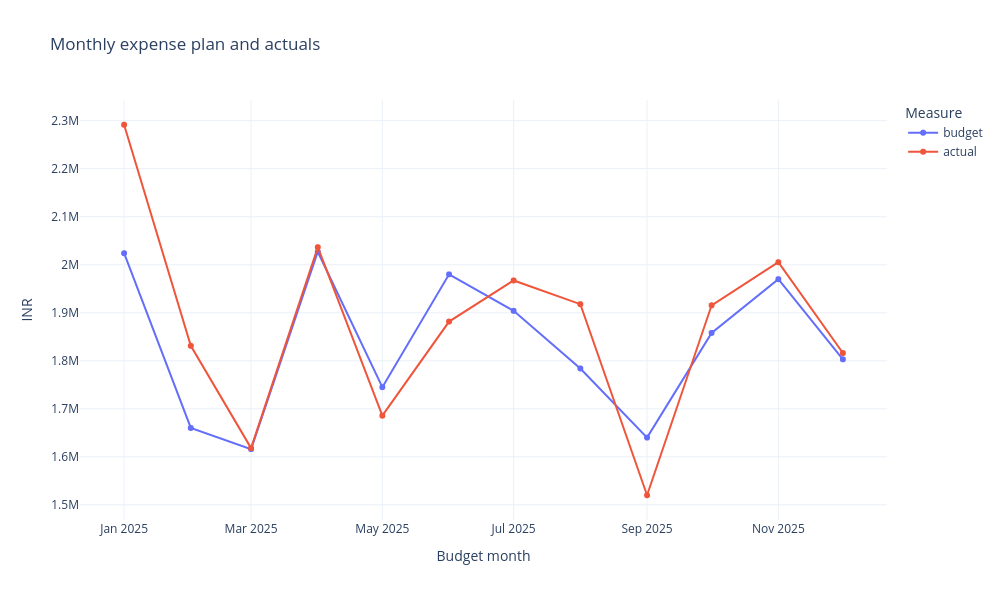

In [18]:
fig = px.line(
    monthly, x='month', y=['budget', 'actual'], markers=True,
    title='Monthly expense plan and actuals',
    labels={'month': 'Budget month', 'value': 'INR', 'variable': 'Measure'},
)
fig.update_layout(template='plotly_white')  # Presentation choice; no data is changed.
# Render this figure directly in the notebook output.
display(fig)

**Interpretation and reasoning**

Each point combines the selected departments and categories for one month. The two lines share the INR scale, so their vertical difference represents net monthly variance. A connecting line does not establish a forecast or explain why spending changed. A cumulative chart would need an explicit chronological `.cumsum()` and would answer a different question.

### Step 17 - Plot department variance around its meaningful zero

**Question:** Which department requires the largest explanation of its net INR gap?

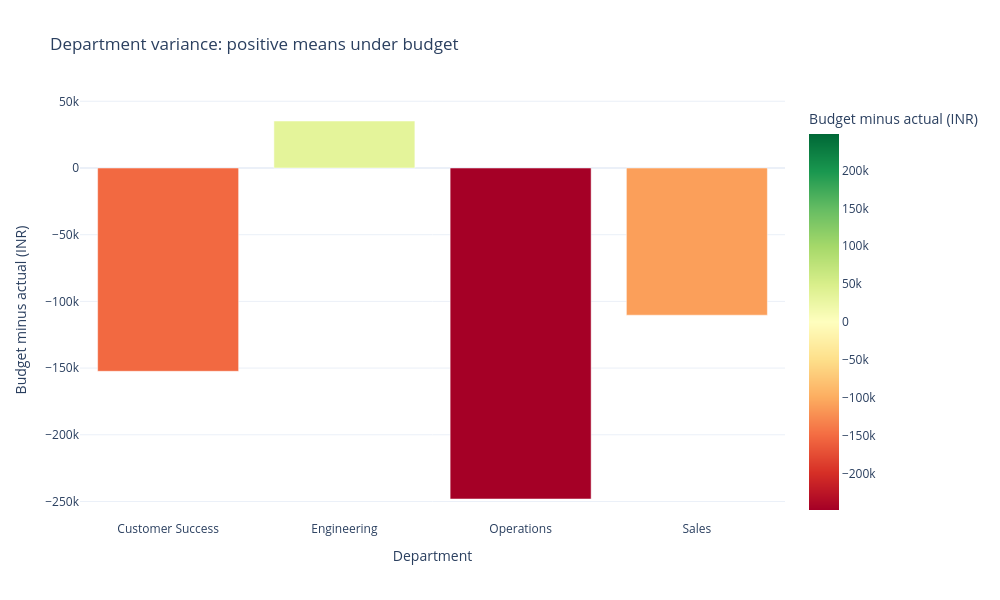

In [19]:
# A bar uses each department's summed variance; a zero midpoint separates over/under budget.
fig = px.bar(
    departments, x='department', y='variance', color='variance',
    color_continuous_scale='RdYlGn', color_continuous_midpoint=0,
    title='Department variance: positive means under budget',
    labels={'department': 'Department', 'variance': 'Budget minus actual (INR)'},
    hover_data=['budget', 'actual', 'utilization_pct'],
)
fig.update_layout(template='plotly_white')
# Render this figure directly in the notebook output.
display(fig)

**Interpretation and reasoning**

Zero is the dividing point between under and over budget, so the chart centers its diverging color scale there. Operations has the largest negative bar. The numeric table remains essential: a large absolute difference may be modest relative to a large approved budget. This ranking alone does not show waste, efficiency, or output delivered.

### Step 18 - See how individual variances are distributed

**Question:** Are negative differences common, and how large are they at line level?

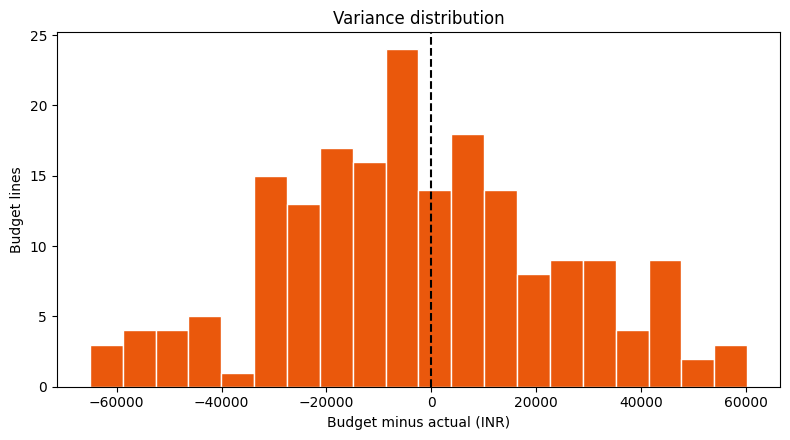

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.5))  # Figure is the canvas; Axes is the plotting area.
ax.hist(filtered['variance'], bins=20, color='#ea580c', edgecolor='white')
ax.axvline(0, color='black', linestyle='--')  # Mark the sign boundary, not a fitted model.
ax.set(title='Variance distribution', xlabel='Budget minus actual (INR)', ylabel='Budget lines')
fig.tight_layout()
# Render this figure directly in the notebook output.
display(fig)
plt.close(fig)  # The saved output remains visible; release the open figure handle.

**Interpretation and reasoning**

The histogram counts budget lines within each INR interval. It does not sum the money in each bin. Values left of zero are overspent; values right are under plan. The 20-bin choice affects visual detail without altering the data. Unusual values are kept for investigation, not automatically discarded. The original app calls `st.pyplot(fig)` and then `plt.close(fig)` to display and clean up a figure during repeated reruns.

### Step 19 - Compare actual-expense distributions by category

**Question:** Which categories have larger or more variable expense lines?

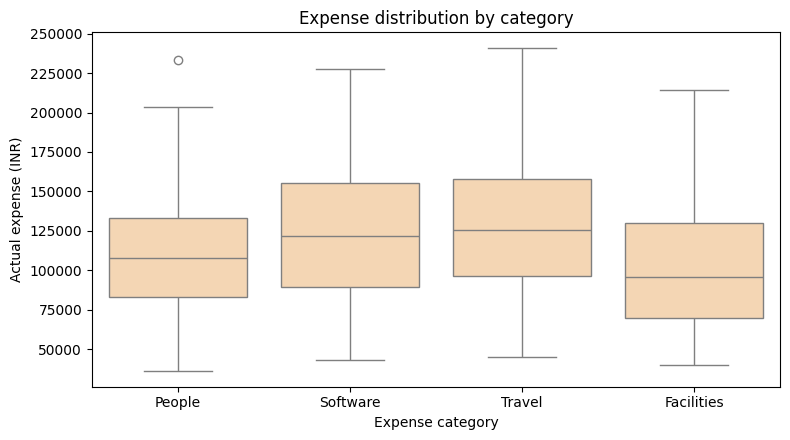

In [21]:
# Show order statistics of individual expense lines rather than category totals or variance.
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=filtered, x='expense_category', y='actual', ax=ax, color='#fed7aa')
ax.set(title='Expense distribution by category', xlabel='Expense category', ylabel='Actual expense (INR)')
fig.tight_layout()
# Render this figure directly in the notebook output.
display(fig)
plt.close(fig)  # The saved output remains visible; release the open figure handle.

**Interpretation and reasoning**

The median is the line inside each box; the box spans the middle half of values. Default whiskers reach observations within 1.5 interquartile ranges, and more distant observations appear separately. This plot uses **actual expense**, not variance: a large expense can be fully planned. Departments and months are mixed within each category unless the data has been filtered.

### Step 20 - Find department/category combinations hidden by totals

**Question:** Where inside each department is the recorded budget gap concentrated?

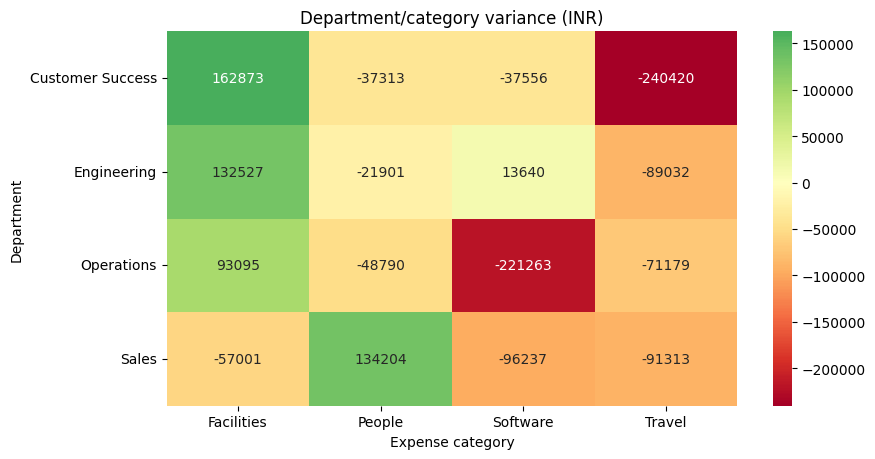

In [22]:
variance_grid = filtered.pivot_table(
    index='department', columns='expense_category', values='variance', aggfunc='sum'
)  # Each cell sums the selected months for one department/category pair.
fig, ax = plt.subplots(figsize=(9, 4.7))
sns.heatmap(variance_grid, annot=True, fmt='.0f', cmap='RdYlGn', center=0, ax=ax)
ax.set(title='Department/category variance (INR)', xlabel='Expense category', ylabel='Department')
fig.tight_layout()
# Render this figure directly in the notebook output.
display(fig)
plt.close(fig)  # The saved output remains visible; release the open figure handle.

**Interpretation and reasoning**

A pivot table places two grouping dimensions on rows and columns. This heatmap contains summed money amounts, not correlation coefficients. A cell can conceal offsetting positive and negative monthly lines, so investigate the source rows before calling the difference recurring. Read the colorbar as well as the annotations: the scale is centered on zero but is not fixed to identical bounds across new selections.

## Inspect and share the evidence

### Step 21 - Summarize numeric values without losing their units

**Question:** What do the central values, spread, and extremes tell us about the selected budget lines?

In [23]:
# Describe selected numeric columns at the original budget-line grain, including variance.
numeric_summary = filtered.select_dtypes(include='number').describe().round(2)
print(numeric_summary.to_string())

          budget     actual  variance
count     192.00     192.00    192.00
mean   114640.62  117118.06  -2477.44
std     39337.33   47095.98  26470.69
min     40000.00   36345.33 -65141.08
25%     82750.00   81542.55 -19718.62
50%    116500.00  113220.07  -3637.25
75%    147000.00  152470.04  14151.71
max    180000.00  240674.94  60233.54


**Interpretation and reasoning**

`describe()` reports available-value counts, means, standard deviations, extrema, and quartiles. The 50% row is the median; 25% and 75% bound the middle half. The derived variance is included because it is numeric. These are line-level distributions, not new monthly or department totals. `.round(2)` changes presentation in this summary table, not the stored transaction values.

### Step 22 - Generate a calculated answer with its scope

**Question:** How can code state a useful finding without hiding which records support it?

In [24]:
# Preserve the selected population and date window alongside the calculated finding.
scope = (
    f'{len(filtered)} selected budget lines; '
    f'{start_date} to {end_date} inclusive; '
    f'departments: {", ".join(selected_departments)}'
)
direction = 'overspend' if actual > budget else 'unspent budget'
answer = (
    f'Actual expense is INR {actual:,.2f} against INR {budget:,.2f} planned. '
    f'The difference is INR {abs(budget - actual):,.2f} of {direction}; '
    f'utilization is {ratio(actual, budget):.2%}.'
)
print(scope)
print(answer)

192 selected budget lines; 2025-01-01 to 2025-12-01 inclusive; departments: Customer Success, Engineering, Operations, Sales
Actual expense is INR 22,486,668.08 against INR 22,011,000.00 planned. The difference is INR 475,668.08 of overspend; utilization is 102.16%.


**Interpretation and reasoning**

An f-string inserts calculated values into a predefined sentence. `abs()` removes the numeric sign only because `direction` supplies the meaning in words. This is deterministic text assembly, not an AI model. The original app also lists selected category values and observed date limits, then assembles six question/answer pairs; the shorter sentence here teaches the same mechanism.

### Step 23 - Create a Markdown report from the same calculations

**Question:** How does a dashboard calculation become a document someone can read or download?

In [25]:
# Tutorial-sized report: the original app has a richer 12-section report.
report_parts = [
    '# Budget analysis - teaching report',
    '## Scope\n' + scope,
    '## Finding\n' + answer,
    '## KPI results\n| Measure | Value |\n| --- | ---: |\n'
    + f'| Budget | INR {budget:,.2f} |\n'
    + f'| Actual | INR {actual:,.2f} |\n'
    + f'| Variance | INR {budget - actual:,.2f} |',
    '## Limit\nExpense differences do not establish profit, cash available, or waste.',
]
teaching_report = '\n\n'.join(report_parts)  # Blank lines separate Markdown sections.
print(teaching_report)

# Budget analysis - teaching report

## Scope
192 selected budget lines; 2025-01-01 to 2025-12-01 inclusive; departments: Customer Success, Engineering, Operations, Sales

## Finding
Actual expense is INR 22,486,668.08 against INR 22,011,000.00 planned. The difference is INR 475,668.08 of overspend; utilization is 102.16%.

## KPI results
| Measure | Value |
| --- | ---: |
| Budget | INR 22,011,000.00 |
| Actual | INR 22,486,668.08 |
| Variance | INR -475,668.08 |

## Limit
Expense differences do not establish profit, cash available, or waste.


**Interpretation and reasoning**

The output is literal Markdown generated from current variables. The report is shorter than the original app's report and is explicitly a tutorial reconstruction. The original builds sections for business context, KPIs, methods, questions, all visuals, quality, next steps, limitations, and reproduction. It displays and downloads one shared `full_report` string; there is no separate reporting dataset.

### Step 24 - Preview exactly what a filtered CSV export contains

**Question:** What will the user receive when downloading the evidence behind the charts?

In [26]:
csv_text = filtered.to_csv(index=False)  # Export source fields plus derived variance.
print('\n'.join(csv_text.splitlines()[:5]))  # Header and four records are enough to inspect.
print(f'Data records in the export: {len(filtered)}')

month,department,expense_category,budget,actual,variance
2025-01-01,Sales,People,112000,131473.15,-19473.149999999994
2025-01-01,Sales,Software,82000,111991.54,-29991.539999999994
2025-01-01,Sales,Travel,172000,119684.36,52315.64
2025-01-01,Sales,Facilities,56000,59246.32,-3246.3199999999997
Data records in the export: 192


**Interpretation and reasoning**

`index=False` omits pandas row labels. The export contains the selected original fields and the derived variance, with the same row grain used by the analysis. Creating this string does not overwrite `department_budget.csv`. Binary floating-point arithmetic can reveal a long decimal tail in an unrounded CSV; display rounding and exact accounting precision are separate concerns. The original app likewise exports its unrounded working table.

### Step 25 - Recalculate a focused question without mutating the baseline

**Question:** Can we trace the portfolio finding back to a specific source record?

In [27]:
# A separate scenario shows how a manager can drill into the largest line.
scenario = frame[
    (frame['department'] == 'Customer Success')
    & (frame['expense_category'] == 'Travel')
    & frame['month'].dt.date.between(pd.Timestamp('2025-02-01').date(), pd.Timestamp('2025-02-01').date())
].copy()
scenario['variance'] = scenario['budget'] - scenario['actual']
print(scenario.to_string(index=False))
print(f'Scenario utilization: {ratio(scenario["actual"].sum(), scenario["budget"].sum()):.2%}')

     month       department expense_category  budget    actual  variance
2025-02-01 Customer Success           Travel  165000 230141.08 -65141.08
Scenario utilization: 139.48%


**Interpretation and reasoning**

Parenthesized conditions joined by `&` form an elementwise AND mask. The scenario preserves the original one-line grain and confirms the INR 65,141.08 overspend identified earlier. It does not explain its cause. In the browser app, the same scenario comes from selecting the department, category, and February 1-February 1 dates. A February 15 start would exclude the February budget line entirely, rather than prorating it.

## Turn the analysis into a Streamlit application

The analysis cells have already supplied the difficult part: correctly defined measures from the correct rows. Streamlit adds controls and display calls around that pipeline. A sidebar selection returns a Python value; pandas uses it to filter rows; `st.metric`, `st.plotly_chart`, `st.pyplot`, and `st.dataframe` present the computed result.

The complete Streamlit reference script below is a **compact reconstruction** of that workflow. It includes the same five chart types and KPI definitions, but a shorter report and less introductory prose than the existing `app.py`. Its comments explain the loading, guard clauses, widget inputs, layout, and exports. Copy only the Python code inside the reference block into `practice_app.py` beside `department_budget.csv`, then run:

```bash
python -m streamlit run practice_app.py
```

In the workshop workspace, use `--server.port 8502` if the built-in dashboard occupies port 8501, then open the forwarded port. Keep the existing `app.py` as the complete original project.

### Checkpoint: translate analysis into an interface

**Predict:** Which calculated objects must change when a user excludes a department? Which quality information still describes the full CSV?

**Inspect:** Find the filters, empty-selection guard, calculations, and displays in the Streamlit reference script. Then inspect the runnable AppTest results for the original app.

**Explain:** Why must filtering happen before calculating cards and charts? How would you check that the exported rows support the displayed answer?

### Step 26 - Build a working browser dashboard from the calculations

**Question:** How do these Python calculations become an interactive tool a finance manager can explore?

## Connect this notebook to the original Streamlit app

The Streamlit teaching script is a compact reference to save separately as Python. Runnable AppTest cells inspect the original [app.py](app.py) without starting a server. This mapping follows that original source.

| Notebook object or operation | Original app connection |
| --- | --- |
| `selected_departments` and `selected_categories` | **Departments** and **Expense categories** multiselects return `selected_department` and `selected_expense_category`. |
| `start_date`, `end_date`, and the Boolean selection | **Date range** returns `dates`; the inclusive date mask creates `filtered`. |
| `budget`, `actual`, and their difference | The first three cards display Budget, Actual spend, and Unspent budget. Negative unspent budget means overspend. |
| `ratio(actual, budget)` | The utilization card formats the ratio as a percentage; a zero budget produces a display fallback of zero, not a meaningful utilization estimate. |
| `monthly` and `departments` | **Finance dashboard** contains the monthly line, variance bars, and departmental table. |
| Selected line-level data and variance pivot | **Explore the data** contains the histogram, expense-category boxplot, and variance heatmap. |
| `filtered` versus `frame` | **Data and quality** exports selected records with variance but reports quality for the whole source. |
| Calculated findings and filter scope | `insights`, `kpi_values`, and `scope` feed `report_parts` and `full_report` in **Full report**. |

A notebook keeps variables in its kernel between cells. Rerun downstream cells after changing selections; restart and run all to check reproducibility. Streamlit normally reruns its script after a sidebar widget changes, rebuilding calculations from widget values. This app rereads the CSV on each rerun and computes all tabs. It does not watch the CSV continuously. Chart hover, zoom, table sorting, and ordinary tab switching do not select a new analytical population.

### Complete Streamlit teaching script - reference

The following complete script is shown in a **Markdown reference cell**. It is intended for the separate `.py` file described above, because Streamlit renders controls and pages through its own server execution. The analysis cells in this notebook have already calculated and explained the measures used here.

```python
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import streamlit as st

st.set_page_config(page_title='Budget versus Actuals', layout='wide')
st.title('Budget versus Actuals')
st.caption('Fictional teaching data | Currency: INR | Variance = budget - actual')

# A saved script can locate the CSV beside itself, regardless of the terminal directory.
data_file = Path(__file__).resolve().with_name('department_budget.csv')
try:
    frame = pd.read_csv(data_file)
    frame['month'] = pd.to_datetime(frame['month'], errors='raise')
    required = ['month', 'department', 'expense_category', 'budget', 'actual']
    if not set(required).issubset(frame.columns) or frame.empty:
        raise ValueError('Provide the required columns and at least one budget line.')
    for column in ['budget', 'actual']:
        frame[column] = pd.to_numeric(frame[column], errors='raise')
    if frame[required].isna().any().any():
        raise ValueError('Fill missing required values first.')
except (OSError, ValueError, KeyError) as error:
    st.error(f'Could not load the dataset: {error}')
    st.stop()  # Do not calculate from invalid or unavailable data.

def ratio(numerator, denominator):
    return numerator / denominator if denominator else 0.0

# Widgets return values; they do not filter the DataFrame by themselves.
departments_chosen = st.sidebar.multiselect(
    'Departments', sorted(frame['department'].unique()),
    default=sorted(frame['department'].unique()), key='practice_finance_departments',
)
categories_chosen = st.sidebar.multiselect(
    'Expense categories', sorted(frame['expense_category'].unique()),
    default=sorted(frame['expense_category'].unique()), key='practice_finance_categories',
)
dates = st.sidebar.date_input(
    'Date range', (frame['month'].min().date(), frame['month'].max().date()),
    min_value=frame['month'].min().date(), max_value=frame['month'].max().date(),
    key='practice_finance_dates',
)
if len(dates) != 2:
    st.info('Choose both a start and an end date.')
    st.stop()

# All outputs below share this one selection, just as in the original app.
filtered = frame[
    frame['department'].isin(departments_chosen)
    & frame['expense_category'].isin(categories_chosen)
    & frame['month'].dt.date.between(dates[0], dates[1])
].copy()
if filtered.empty:
    st.info('No rows match these filters.')
    st.stop()
filtered['variance'] = filtered['budget'] - filtered['actual']
budget, actual = filtered['budget'].sum(), filtered['actual'].sum()

# Format the same numeric values as browser KPI cards.
cards = st.columns(4)
cards[0].metric('Budget (INR)', f'{budget:,.0f}')
cards[1].metric('Actual spend (INR)', f'{actual:,.0f}')
cards[2].metric('Unspent budget (INR)', f'{budget - actual:,.0f}')
cards[3].metric('Budget utilization', f'{ratio(actual, budget):.1%}')
st.caption('A negative variance means overspend. Zero-budget utilization is undefined despite the helper fallback.')

monthly = filtered.groupby('month', as_index=False)[['budget', 'actual']].sum()
departments = filtered.groupby('department', as_index=False)[['budget', 'actual', 'variance']].sum()
departments['utilization_pct'] = 100 * departments['actual'].div(departments['budget'].replace(0, float('nan')))

# Tabs are display containers, not conditional or lazy computations.
dashboard, explore, records, report_tab = st.tabs(['Dashboard', 'Explore', 'Data', 'Report'])
with dashboard:
    st.plotly_chart(px.line(monthly, x='month', y=['budget', 'actual'], markers=True,
                           title='Monthly expense plan and actuals'), use_container_width=True)
    st.plotly_chart(px.bar(departments, x='department', y='variance', color='variance',
                          color_continuous_scale='RdYlGn', color_continuous_midpoint=0,
                          title='Positive variance is under budget'), use_container_width=True)
    st.dataframe(departments.round(2), hide_index=True)
with explore:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(filtered['variance'], bins=20, color='#ea580c', edgecolor='white')
    ax.axvline(0, color='black', linestyle='--')
    ax.set(title='Variance distribution', xlabel='Variance (INR)', ylabel='Budget lines')
    st.pyplot(fig)
    plt.close(fig)  # Repeated browser reruns should not accumulate open figures.
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.boxplot(data=filtered, x='expense_category', y='actual', ax=ax, color='#fed7aa')
    ax.set_title('Expense distribution by category')
    st.pyplot(fig)
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(9, 4))
    grid = filtered.pivot_table(index='department', columns='expense_category', values='variance', aggfunc='sum')
    sns.heatmap(grid, annot=True, fmt='.0f', cmap='RdYlGn', center=0, ax=ax)
    ax.set_title('Department/category variance (INR)')
    st.pyplot(fig)
    plt.close(fig)
with records:
    st.dataframe(filtered, hide_index=True)
    st.download_button('Download filtered CSV', filtered.to_csv(index=False),
                       'filtered_department_budget.csv', 'text/csv')

# This compact report uses current values; the original app supplies 12 richer sections.
report = '\n\n'.join([
    '# Budget analysis',
    f'Selected budget lines: {len(filtered)}; requested dates: {dates[0]} to {dates[1]}.',
    f'Budget: INR {budget:,.2f}; actual: INR {actual:,.2f}; variance: INR {budget - actual:,.2f}.',
    f'Utilization: {ratio(actual, budget):.2%}.',
    'Negative variance means overspend. This expense dataset does not establish profit, cash, or waste.',
])
with report_tab:
    st.download_button('Download teaching report', report, 'finance_teaching_report.md', 'text/markdown')
    st.markdown(report)
```

## Inspect the actual Streamlit application from this notebook

The companion script above is a compact teaching reconstruction. The next executable cells inspect the **existing sibling `app.py`**, which also contains the complete business context, chart explanations and full report.

`AppTest` is Streamlit's testing interface. It runs the application and lets Python inspect the UI elements it produced. It does not start a browser server. We use it here to connect the notebook's calculations with the application's real labels and values. The displayed tables summarize application elements; they are not browser screenshots.

### Load and run the sibling app

`AppTest.from_file(...)` reads a saved Streamlit script; `.run()` executes it with default widget values. The checks stop this cell if the app raises an exception or displays a loading error. Keeping `app.py` beside its CSV lets its `Path(__file__)` lookup work independently of notebook variables.

In [28]:
from streamlit.testing.v1 import AppTest  # Inspect Streamlit output without launching a server.
import logging

# AppTest intentionally runs without a browser session; quiet its context-only warning.
# Application errors are still checked explicitly below.
logging.getLogger('streamlit.runtime.scriptrunner_utils.script_run_context').setLevel(logging.ERROR)

app_file = PROJECT_DIR / 'app.py'
app_preview = AppTest.from_file(str(app_file), default_timeout=45).run()
if len(app_preview.exception):
    raise RuntimeError('; '.join(str(error.value) for error in app_preview.exception))
if len(app_preview.error):
    raise RuntimeError('; '.join(str(error.value) for error in app_preview.error))

print('Script:', app_file.name)
print('Title:', app_preview.title[0].value)
print('Default application run completed.')

Script: app.py
Title: Budget versus Actuals
Default application run completed.


### Read the controls, KPI cards and output containers

The values below come from the application instance that just ran. A metric element has a `label` and a formatted `value`; a multiselect has the current list of choices. The table dimensions describe what the app actually rendered. Chart counts distinguish interactive Plotly figures from Matplotlib/Seaborn images.

In [29]:
# Turn rendered KPI cards into an ordinary table we can inspect in the notebook.
baseline_cards = {metric.label: metric.value for metric in app_preview.metric}
display(pd.DataFrame(baseline_cards.items(), columns=['Dashboard measure', 'Displayed value']))

for widget in app_preview.multiselect:
    print(widget.label + ': ' + ', '.join(map(str, widget.value)))
for widget in app_preview.date_input:
    print(widget.label + ': ' + ' to '.join(map(str, widget.value)))
for widget in app_preview.slider:
    print(widget.label + ': ' + str(widget.value))
for index, table in enumerate(app_preview.dataframe, start=1):
    print(f'Table {index}: {len(table.value)} rows x {len(table.value.columns)} columns')
print('Interactive Plotly charts:', len(app_preview.get('plotly_chart')))
print('Rendered statistical charts:', len(app_preview.get('imgs')))
for button in app_preview.get('download_button'):
    print('Download:', button.proto.label)

,Dashboard measure,Displayed value
0,Budget (INR),"22,011,000"
1,Actual spend (INR),"22,486,668"
2,Unspent budget (INR),"-475,668"
3,Budget utilization,102.2%


Departments: Customer Success, Engineering, Operations, Sales
Expense categories: Facilities, People, Software, Travel
Date range: 2025-01-01 to 2025-12-01
Table 1: 4 rows x 3 columns
Table 2: 4 rows x 5 columns
Table 3: 5 rows x 2 columns
Table 4: 192 rows x 6 columns
Table 5: 8 rows x 3 columns
Table 6: 5 rows x 3 columns
Interactive Plotly charts: 2
Rendered statistical charts: 3
Download: Download filtered CSV
Download: Download full report (Markdown)


### Change one filter and observe a real app rerun

This cell selects one value in the first multiselect and compares the resulting KPI cards with the baseline. `.set_value(...)` changes the control; `.run()` executes the app again. We then restore the complete selection so the preview ends in its default state.

The notebook's own `frame` and `filtered` variables belong to the analysis session. `AppTest` executes the script in its own application context, so changing this preview does not silently alter the earlier notebook analysis. In the live browser app, the corresponding widget interaction triggers the rerun for you.

In [30]:
# Keep all original choices so the application can be restored after this experiment.
first_control = app_preview.multiselect[0]
original_choices = list(first_control.value)
one_choice = original_choices[0]
control_label = first_control.label

# This is the programmatic equivalent of narrowing a sidebar multiselect.
first_control.set_value([one_choice]).run()
if len(app_preview.exception) or len(app_preview.error):
    raise RuntimeError('The narrowed app selection did not complete successfully.')
selected_cards = {metric.label: metric.value for metric in app_preview.metric}
comparison = pd.DataFrame({
    'Dashboard measure': list(baseline_cards),
    'All choices': list(baseline_cards.values()),
    f'{control_label}: {one_choice}': [selected_cards[label] for label in baseline_cards],
})
display(comparison)

# Restore the baseline; the notebook data and the source CSV have not been edited.
app_preview.multiselect[0].set_value(original_choices).run()
if len(app_preview.exception) or len(app_preview.error):
    raise RuntimeError('The application could not restore its original selection.')
print('Restored', control_label + ':', ', '.join(map(str, original_choices)))

,Dashboard measure,All choices,Departments: Customer Success
0,Budget (INR),"22,011,000","5,671,000"
1,Actual spend (INR),"22,486,668","5,823,416"
2,Unspent budget (INR),"-475,668","-152,416"
3,Budget utilization,102.2%,102.7%


Restored Departments: Customer Success, Engineering, Operations, Sales


### Open the browser interface

In a **terminal in this project folder**, run:

```bash
python -m streamlit run app.py --server.port 8502
```

Open the displayed local URL, or forward port 8502 in Cloud Labs. The built-in workshop dashboard uses port 8501. Streamlit keeps running while the page is available; stop it with **Ctrl+C** in that terminal. This command is a terminal instruction, so **Run All** in this notebook does not start the server.

Follow one choice through the app: widget value → pandas row selection → derived columns → grouped results → cards/charts/report. This is the connection between the analysis and its browser interface.

## Understand the original app and its limits

The compact script demonstrates the application mechanics. The existing [app.py](app.py) adds reusable `CASE`, `DECISION`, `DATA_CONTEXT`, `FORMULAS`, `VISUAL_GUIDE`, `RECOMMENDATIONS`, `LIMITATIONS`, and `FIELD_GUIDE` values. They keep business explanations consistent across the interface and report. `explain_visual(index, container=st)` selects a five-part guide and places its title, purpose, reading instructions, question, and caution beneath the corresponding chart.

Its `insights` list contains six calculated question/answer pairs. The first three appear near the top of the page; the complete set appears in the 12-section report. `report_parts` combines those values with static explanations, source-quality counts, and scope strings. `report_parts[5]` is the **KPI results** section because the title occupies index zero; that is where the original code appends its field dictionary. Joining the list creates one `full_report` used both for display and download. The Markdown export contains chart explanations rather than embedded chart images.

The original source-quality panel uses full `frame`, while metrics, charts, insights, and CSV downloads use `filtered`. Its numeric summary includes derived variance. Exact duplicate rows are reported, not removed; business-key uniqueness is not enforced. The loaded case text describes the bundled 192-line dataset and will not rewrite itself if you substitute a different CSV.

### What to check before drawing a conclusion

- **Denominators:** Zero budget makes utilization undefined. The scalar helper returns a display safeguard, while grouped percentages use missing values. Negative or infinite input is not rejected by numeric parsing alone.
- **Date scope:** First-of-month labels select whole recorded budget lines. A mid-month start excludes that month's label; there is no prorating.
- **Aggregation:** Line-level overspend can be hidden by offsetting underspend. Department and monthly minima describe different groups.
- **Ties:** `idxmin()` returns the first matching label. A grouped minimum follows sorted group order by default; an individual-row minimum follows the first matching source row. Inspect ties before describing a unique worst case.
- **Business meaning:** Underspend is not profit or available cash. Overspend does not establish waste. Income, commitments, accrual timing, revised plans, and output are missing.
- **Validation scope:** The loader checks required columns, nonempty input, parseability, and missing required values. It does not validate finite/nonnegative amounts, month-start consistency, business-key uniqueness, or accounting classifications. Later calculation/plot failures fall outside its loading `try` block.

### Useful next experiments

Change `selected_departments` and rerun the analysis from the filter cell onward. Compare equivalent six-month windows. Add a cumulative view by sorting monthly totals and applying `.cumsum()`, then label it as cumulative **within the selected period**. Put both net variance and gross line overspend in an explanation and state why they differ. Each exercise should preserve a traceable path from source rows to formula to reported conclusion.

If imports fail, check the active Python environment. If the file is missing, check the working directory for notebook cells and the sibling CSV path for the Streamlit script. Complete both date endpoints and retain at least one selection when the app shows an empty-state message. Save CSV edits and rerun to see them; the app does not implement a continuous data feed.

## References

- [Original app](app.py), [source CSV](department_budget.csv), [workshop setup](../README.md), and [repository setup](../../README.md) establish the project behavior and data used here.
- [pandas 2.2 introduction](https://pandas.pydata.org/pandas-docs/version/2.2/user_guide/10min.html), [indexing](https://pandas.pydata.org/pandas-docs/version/2.2/user_guide/indexing.html), and [grouping](https://pandas.pydata.org/pandas-docs/version/2.2/user_guide/groupby.html) explain the table operations.
- [Streamlit run instructions](https://docs.streamlit.io/develop/concepts/architecture/run-your-app) and [Streamlit 1.50 tabs](https://docs.streamlit.io/1.50.0/develop/api-reference/layout/st.tabs) explain execution and container behavior.
- [Plotly Express](https://plotly.com/python/plotly-express/), [Matplotlib histograms](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html), [Seaborn boxplots](https://seaborn.pydata.org/generated/seaborn.boxplot.html), and [Seaborn heatmaps](https://seaborn.pydata.org/generated/seaborn.heatmap.html) document the visualization tools.

## Practice making an analytical recommendation

1. **Explain a department's spending position.** Select one department, keeping categories and period consistent. Report both its net variance and number of overspent lines. **Hint:** derive variance on your selected rows before counting negatives; aggregate only afterward. **Interpret:** What can the line count reveal that the department total hides? What evidence would you request before deciding that spending was wasteful?

2. **Compare the two halves of the year.** Filter separate copies of `frame` and recalculate each half's totals and utilization. **Hint:** preserve the same department/category selection and divide each half's summed actual by its summed budget. **Interpret:** Does a smaller currency gap necessarily imply better proportional adherence? Explain the period and denominator with your answer.

3. **Add a cumulative comparison.** Extend the monthly table with cumulative budget and actual expense and plot both. **Hint:** sort by `month` before `cumsum()` and state where the accumulation begins. **Interpret:** How can the cumulative chart hide a recent monthly problem? Retain the monthly view for that question.

Before presenting, check that you can state the selected population, define the variance sign, name every denominator, trace one result to source rows, distinguish net from gross overspending, and propose an investigation rather than claim an unobserved cause.

## Finish with an explanation you can defend

Before presenting the project, explain one complete chain in your own words: **the question, the source rows, the operation, the result, and the decision it informs**. State the units and denominator. Show a supporting table or chart and one limitation. Then restart the kernel and run the notebook from the top to confirm that the result does not depend on forgotten interactive state.

Notebook and application references: [Jupyter notebook structure](https://nbformat.readthedocs.io/en/latest/format_description.html), [Plotly notebook renderers](https://plotly.com/python/renderers/), and [Streamlit 1.50 AppTest](https://docs.streamlit.io/1.50.0/develop/api-reference/app-testing/st.testing.v1.apptest).